# Experiment 3 — Module 2: Advanced Autoregressive Decoding & Context Sweeps

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/deepanshu-yadav/EVO_2_PETase/blob/main/experiments/experiment_3_deep_exploration/module_2_decoding_sweeps/exp3_module_2_decoding_and_scaling_sweeps.ipynb)

Show Evo 2 a handful of members of the PETase family, separated by a fixed nucleotide spacer (`GGGGGGGG`), and let it continue the sequence. The continuation is a new coding sequence.

In **Experiment 3 — Module 2**, we apply the thermally stratified and cluster-balanced prompt suites created in Module 1 to investigate three primary scientific objectives:

1. **Novelty–Validity Pareto Frontier:** How does decoding temperature $T \in \{0.6, 0.8, 1.0, 1.1\}$ (with bounded top-$k=4$ and nucleus top-$p=0.92$) balance mature fold coherence against sequence exploration?
2. **Context Depth Scaling & Memorization Cliff:** How does context depth scaling $n \in \{8, 16, 32, 64\}$ affect novelty, and at what context depth does sequence memorization spike ($\overline{\max \text{PID}} > 80.0\%$ with a novel yield drop $> 25\%$)?
3. **Contrastive Statistical Enrichment:** Using paired thermophilic cutinase prompts vs general background prompts (`prompts_contrastive.json`), we score contrastive log-likelihood reranking:
   $$\Delta \text{LL}(x) = \log P_{\text{Evo2}}(x \mid \text{Prompt}_{\text{thermo}}) - \log P_{\text{Evo2}}(x \mid \text{Prompt}_{\text{general}})$$
   isolating sequences statistically enriched in thermophilic determinants.

> **Robust Execution & Checkpointing:** Real-time verbose logging streams current batch status and latency to both the console and `work/generation.log`. Every batch immediately writes a JSON checkpoint (`work/checkpoints/gen_{cell_id}.json`), allowing interrupted sweeps to resume instantly without re-generating.

---
### Hardware and Time
- **GPU:** One with $\ge 24$ GB — Colab **A100** or **L4**.
- **Disk:** ~15 GB for the Evo 2 7B checkpoint.
- **Time:** ~5 min environment setup, then continuous-batch generation across context depths and temperatures.


## 1 · Environment

Confirm the runtime has a GPU, then install dependencies. **Runtime → Change runtime type → A100 GPU** (or L4) if the next cell reports no device.


In [ ]:
import subprocess

print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version",
                      "--format=csv"], capture_output=True, text=True).stdout)


### Install

**Two environments, on purpose.** Colab's kernel is Python 3.13 and its version cannot be changed. evo2-flash requires `<3.13`, and vLLM 0.26 needs a specific CUDA 12.9 torch build that would collide with Colab's preinstalled one. So the engine gets a dedicated Python 3.12 venv (`uv venv`) and the kernel is left alone. Cells that need the engine call that venv's Python; the analysis half runs in the kernel.


In [1]:
#@title Dual-Environment Setup (~5 minutes)
ENVDIR = "/content/evo2env"

# vLLM 0.26.0, CUDA 12.9 build
VLLM_WHEEL = ("https://github.com/vllm-project/vllm/releases/download/v0.26.0/"
              "vllm-0.26.0+cu129-cp38-abi3-manylinux_2_28_x86_64.whl")

!pip install -q uv
!uv venv -q --seed --python 3.12 {ENVDIR}

# Torch stack pinned to the exact +cu129 builds of the A100/L4 reference runs
!{ENVDIR}/bin/pip install -q torch==2.11.0+cu129 torchvision==0.26.0+cu129 \
    torchaudio==2.11.0+cu129 torchcodec==0.15.0+cu129 \
    --extra-index-url https://download.pytorch.org/whl/cu129

!{ENVDIR}/bin/pip install -q "{VLLM_WHEEL}" \
    --extra-index-url https://download.pytorch.org/whl/cu129

# ninja + evo2-flash inside the venv
!{ENVDIR}/bin/pip install -q ninja evo2-flash

# Analysis libraries in the Colab kernel
!pip install -q biopython pandas numpy matplotlib seaborn openpyxl

# MMseqs2 static Linux AVX2 build -> ./mmseqs/bin/mmseqs
!wget -qO- https://mmseqs.com/latest/mmseqs-linux-avx2.tar.gz | tar xz


In [2]:
#@title Verify Environment Integration
import os, shutil, subprocess

PY = f"{ENVDIR}/bin/python"
os.environ.update(
    VLLM_ENABLE_V1_MULTIPROCESSING="0",   # the Evo2 API needs the engine in-process
    TOKENIZERS_PARALLELISM="false",
    HF_HUB_DISABLE_TELEMETRY="1",
    PATH=f"{ENVDIR}/bin:/usr/local/cuda/bin:" + os.environ["PATH"],
)

MMSEQS = shutil.which("mmseqs") or os.path.abspath("mmseqs/bin/mmseqs")
assert os.path.exists(MMSEQS), "mmseqs not found -- re-run the install cell"
print(subprocess.run([MMSEQS, "version"], capture_output=True, text=True).stdout.strip())

CHECK = """
import sys, torch, vllm, evo2_flash
assert "+cu12" in torch.__version__, (
    f"torch is {torch.__version__}; vLLM's cu129 build needs a +cu129 torch, or it fails "
    f"with 'libcudart.so.12: cannot open shared object file'. Re-run the install cell.")
print(f"venv: python {sys.version.split()[0]} | torch {torch.__version__} "
      f"| vllm {vllm.__version__} | cuda {torch.cuda.is_available()}")
"""
r = subprocess.run([PY, "-c", CHECK], capture_output=True, text=True)
print(r.stdout.strip() or r.stderr[-3000:])
r.check_returncode()


ae60ef6964f3de689139bcfe290d9fad18f70b06
venv: python 3.12.3 | torch 2.11.0+cu129 | vllm 0.26.0 | cuda True


## 2 · Data Ingestion & Prompt Suites

We load:
1. **Reference Pool & Codon Cache:** `petase_pool.fasta` and `petase_codons.json` — verified using `load_pool()` to ensure 100% codon-to-protein correspondence.
2. **Stratified Curriculum Prompts:** `prompts_thermo_curriculum.json` — engineered in Module 1 with cluster balancing (70% PID) and ascending $T_m$ curriculum ordering.
3. **Contrastive Paired Prompts:** `prompts_contrastive.json` — paired thermophilic vs general background prompts for Delta-LL scoring.


In [3]:
#@title Load Reference Pool, Codons & Prompt Suites
import json, pathlib, urllib.request, shutil

RAW = ("https://raw.githubusercontent.com/deepanshu-yadav/EVO_2_PETase/refs/heads/main/prepared_data/three_datasets_16nov2026/")
REPO_BASE = ("https://raw.githubusercontent.com/deepanshu-yadav/EVO_2_PETase/refs/heads/main/")
DATA = pathlib.Path("data")
OUTPUTS = pathlib.Path("outputs")
DATA.mkdir(exist_ok=True)
OUTPUTS.mkdir(exist_ok=True)

# 1. Download core pool & codon cache if not present
for name in ["petase_pool.fasta", "petase_codons.json"]:
    if not (DATA / name).exists():
        urllib.request.urlretrieve(f"{RAW}/{name}", DATA / name)
        print(f"downloaded {name}")


def load_pool(path):
    """Protein sequences in FASTA order, cleaned as the reference pipeline does.

    petase is wrapped at 60 columns, so a line-based loader would return 320 fragments
    instead of 64 proteins. Order matters: the example draw indexes into this list.
    """
    seqs, cur = [], None
    for line in open(path):
        if line.startswith(">"):
            if cur:
                seqs.append(cur)
            cur = ""
        elif cur is not None:
            cur += line.strip()
    if cur:
        seqs.append(cur)
    return [s for s in (x.upper().replace("*", "") for x in seqs) if s]

pool_proteins = load_pool(DATA / "petase_pool.fasta")
cache = json.loads((DATA / "petase_codons.json").read_text())
assert cache["proteins"] == pool_proteins, "Codon cache does not match petase_pool.fasta!"
print(f"Loaded {len(pool_proteins)} proteins from petase_pool.fasta; codon cache verified.")

# 2. Ingest Module 1 prompt suites (prompts_thermo_curriculum.json & prompts_contrastive.json)
PROMPT_FILES = ["prompts_thermo_curriculum.json", "prompts_contrastive.json"]
for pf in PROMPT_FILES:
    dest = OUTPUTS / pf
    local_src = pathlib.Path(f"experiments/experiment_3_deep_exploration/outputs/{pf}")
    if local_src.exists():
        shutil.copy(local_src, dest)
        print(f"Loaded local {pf}")
    elif not dest.exists():
        try:
            url = f"{REPO_BASE}/experiments/experiment_3_deep_exploration/outputs/{pf}"
            urllib.request.urlretrieve(url, dest)
            print(f"Downloaded {pf}")
        except Exception as e:
            print(f"Note: {pf} download pending or local ({e})")


downloaded petase_pool.fasta
downloaded petase_codons.json
Loaded 139 proteins from petase_pool.fasta; codon cache verified.
Downloaded prompts_thermo_curriculum.json
Downloaded prompts_contrastive.json


## 3 · Configuration

The prompt is composed using the canonical left-layout delimiter structure:
`SPACER s1 SPACER s2 … SPACER sK SPACER`

For Experiment 3, we configure:
- **Temperature Grid:** $T \in \{0.6, 0.8, 1.0, 1.1\}$ (sweeping across the novelty-validity frontier).
- **Context Depths:** $n \in \{8, 16, 32, 64\}$ (probing context depth scaling and detecting the memorization cliff).
- **Bounded Sampling:** `TOP_K = 4`, `TOP_P = 0.92`, `MIN_P = 0.05`.


In [4]:
#@title Experiment Configuration (Decoding Sweeps & Context Grid)

TEMPERATURES       = [0.6, 0.8, 1.0]   # Decoding temperatures sweep
TOP_K              = 4                      # Reference pipeline bounding value
TOP_P              = 0.92                   # Nucleus filter cutoff
MIN_P              = 0.05                   # Min-p truncation

SPACER             = "GGGGGGGG"             # Fixed nucleotide separator
SEED               = 1337                   # Master RNG seed; draw p uses SEED + p
N_PROMPTS          = 10                     # Independent example draws per cell (published sweep: 25)
SAMPLES_PER_PROMPT = 4                      # Replicates per prompt draw (4 -> 40 samples per cell)

MAX_ID             = 85.0                   # Novelty threshold: max %ID to pool < 85.0%
GPU_MEM_FRACTION   = 0.85                   # vLLM GPU memory utilization
MODEL_NAME         = "evo2_7b"

FAMILIES = {
    "petase": dict(
        label="petase",
        fasta="petase_pool.fasta",
        codons="petase_codons.json",
        n_examples=[8, 16, 32, 64],          # Context depth scaling grid
        evalue=0.01,                        # MMseqs significance threshold
    )
}


## 4 · Build the Prompts

Construct the multi-exemplar context prompts using the canonical left-layout delimiter structure:
A spacer precedes every example, plus a trailing spacer where the model continues into the new sequence.

If `prompts_thermo_curriculum.json` from Module 1 is present, its cluster-balanced and $T_m$-curriculum ordered draws are utilized. Otherwise, prompts are composed live on the fly directly from the verified codon cache.


In [6]:
#@title Construct Prompts & In-Context Cells
import random


def select_examples(pool, n, seed):
    random.seed(seed)
    return random.sample(pool, min(n, len(pool)))


def compose_prompt(dna_seqs, spacer=SPACER):
    """left layout: a spacer before every example, plus a trailing one."""
    return "".join(spacer + s for s in dna_seqs) + spacer


def extract_cds(continuation, spacer=SPACER):
    """The prompt ended on a separator, so the CDS is everything before the next one."""
    return continuation.split(spacer)[0] if spacer in continuation else None


def build_cells(fam_key, cache, temperatures=TEMPERATURES):
    proteins, dna = cache["proteins"], cache["dna"]
    assert len(set(proteins)) == len(proteins), f"{fam_key}: duplicate pool sequences"
    dna_of = dict(zip(proteins, dna))

    # Check if pre-engineered curriculum suite is available from Module 1
    curriculum_file = OUTPUTS / "prompts_thermo_curriculum.json"
    suite_cells_by_n = {}
    if curriculum_file.exists():
        suite_data = json.loads(curriculum_file.read_text())
        suite_cells_by_n = {c["n_examples"]: c for c in suite_data.get("cells", [])}
        print(f"Loaded pre-engineered Module 1 curriculum suite ({len(suite_cells_by_n)} depths available)")

    cells = []
    for n in FAMILIES[fam_key]["n_examples"]:
        if n > len(proteins):
            print(f"  {fam_key}: skipping n={n} (pool has {len(proteins)})")
            continue

        if n in suite_cells_by_n:
            # Use Module 1 cluster-balanced & Tm-curriculum draws
            src_cell = suite_cells_by_n[n]
            src_draws = src_cell["draws"][:N_PROMPTS]
            cell_gen_len = src_cell.get("gen_length", max(map(len, proteins)) * 3 + 30)
            draws = []
            for i, d in enumerate(src_draws):
                draw_gen_len = d.get("gen_length")
                if draw_gen_len is None:
                    if d.get("max_exemplar_aa_len"):
                        draw_gen_len = d["max_exemplar_aa_len"] * 3 + 30
                    else:
                        draw_gen_len = cell_gen_len
                draws.append(dict(
                    prompt_idx=i,
                    prompt=d["prompt"],
                    gen_length=draw_gen_len,
                ))
        else:
            # Live on-the-fly prompt composition from codon cache
            draws = []
            for p in range(N_PROMPTS):
                sel = select_examples(proteins, n, SEED + p)
                prompt = compose_prompt([dna_of[a] for a in sel])
                assert prompt.count(SPACER) == n + 1
                assert prompt.startswith(SPACER) and prompt.endswith(SPACER)
                draws.append(dict(prompt_idx=p, prompt=prompt,
                                  gen_length=max(map(len, sel)) * 3 + 30))

        # For Experiment 3, generate cells across context depths and temperatures
        for temp in temperatures:
            cell_id = f"{fam_key}_n{n:03d}_T{temp:.1f}"
            cells.append(dict(
                cell_id=cell_id,
                family=fam_key, n_examples=n, temperature=temp, draws=draws,
                pool_lo=min(map(len, proteins)), pool_hi=max(map(len, proteins)),
                evalue=FAMILIES[fam_key]["evalue"],
                # One budget per cell, so the whole cell goes into one batched call.
                gen_length=max(d["gen_length"] for d in draws),
            ))
    return cells


CELLS = []
for fam, info in FAMILIES.items():
    lens = [len(s) for s in cache["proteins"]]
    print(f"{fam:>5}  {len(lens)} proteins, {min(lens)}-{max(lens)} aa, "
          f"codon-optimized for {cache['organism']}")
    CELLS += build_cells(fam, cache)

prefill = sum(len(d["prompt"]) for c in CELLS for d in c["draws"])
decode = sum(c["gen_length"] * N_PROMPTS * SAMPLES_PER_PROMPT for c in CELLS)
longest = max(len(d["prompt"]) + c["gen_length"] for c in CELLS for d in c["draws"])
print(f"\n{len(CELLS)} cells x {N_PROMPTS} draws x {SAMPLES_PER_PROMPT} samples = "
      f"{len(CELLS) * N_PROMPTS * SAMPLES_PER_PROMPT} sequences")
print(f"  unique prefill {prefill:,} nt   decode {decode:,} nt   "
      f"longest context {longest:,} nt")

petase  139 proteins, 241-306 aa, codon-optimized for Escherichia coli general
Loaded pre-engineered Module 1 curriculum suite (4 depths available)

12 cells x 10 draws x 4 samples = 480 sequences
  unique prefill 2,908,770 nt   decode 455,040 nt   longest context 52,714 nt


## 5 · Generate

The engine lives in the dedicated Python 3.12 venv, so generation executes via an out-of-process script (`generate.py`), identical to `exp1_initial_discovery.ipynb`.

### Live Monitoring & Instant Checkpointing:
- **Verbose Logging:** Real-time timing, throughput (nt/s), and continuous prefix-cache hit rates stream live to the console and are saved to `work/generation.log`.
- **JSON Checkpointing:** Every completed cell immediately writes its sequences and timing metadata to `work/checkpoints/gen_{cell_id}.json`. If interrupted, re-running automatically resumes without duplicating compute.
- **Bottleneck Profiling:** Identifies exactly which context depths and temperatures took the longest.


In [7]:
#@title Autoregressive Generation with Live Verbose Logging & Checkpointing
import datetime, json, pathlib, subprocess, time
import pandas as pd

GEN_SCRIPT = r"""
# Generation stage -- runs in the evo2env venv, not the Colab kernel.
import datetime, json, pathlib, time
from evo2_flash import Evo2

WORK = pathlib.Path("work")
CKPT_DIR = WORK / "checkpoints"
CKPT_DIR.mkdir(parents=True, exist_ok=True)
LOG_FILE = WORK / "generation.log"

def log(msg):
    ts = datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    line = f"[{ts}] {msg}"
    print(line, flush=True)
    with open(LOG_FILE, "a", encoding="utf-8") as f:
        f.write(line + "\n")

cfg = json.loads((WORK / "cells.json").read_text())
cells = cfg["cells"]
longest = max(len(p) + c["gen_length"] for c in cells for p in c["prompts"])

log(f"Initializing Evo 2 ({cfg['model']}, gpu_mem={cfg['gpu_memory_utilization']})...")
model = Evo2(cfg["model"], gpu_memory_utilization=cfg["gpu_memory_utilization"])
log(f"Evo 2 online. max_model_len = {model.max_model_len:,}")
if model.max_model_len < longest:
    raise SystemExit(
        f"the longest cell needs {longest:,} positions but max_model_len is "
        f"{model.max_model_len:,}. Drop the largest n from a family's grid, or pass "
        f"Evo2(..., kv_cache_dtype='fp8') to double KV capacity.")

timing_records = []
t0 = time.time()
total_cells = len(cells)

for i, c in enumerate(cells, 1):
    cell_id = c["cell_id"]
    ckpt_file = CKPT_DIR / f"gen_{cell_id}.json"

    # Checkpoint Resume check
    if ckpt_file.exists():
        try:
            saved = json.loads(ckpt_file.read_text())
            log(f"[{i:>2}/{total_cells}] ({(i/total_cells)*100:4.1f}%) RESUMED {cell_id} from checkpoint ({len(saved['sequences'])} seqs)")
            timing_records.append(saved.get("timing", {
                "cell_id": cell_id, "n_examples": c["n_examples"], "temperature": c["temperature"],
                "elapsed_s": 0.0, "status": "resumed_from_cache"
            }))
            continue
        except Exception:
            pass

    prompt_count = len(c["prompts"])
    max_prompt_len = max(len(p) for p in c["prompts"])
    total_prefill_nt = sum(len(p) for p in c["prompts"])
    expected_decode_nt = prompt_count * c["gen_length"]

    log(f"\n[{i:>2}/{total_cells}] ({(i/total_cells)*100:4.1f}%) STARTING {cell_id} | n={c['n_examples']} | T={c['temperature']:.1f}")
    log(f"      Prompts: {prompt_count} draws | Max Context: {max_prompt_len:,} nt | Decode Budget: {c['gen_length']} nt/seq")
    log(f"      Batch Prefill: {total_prefill_nt:,} nt | Expected Decode: {expected_decode_nt:,} nt")

    t_start = time.time()
    out = model.generate(
        c["prompts"], n_tokens=c["gen_length"],
        temperature=c["temperature"], top_k=cfg["top_k"], top_p=cfg["top_p"],
        seed=cfg["seed"] + 1000 * i,   # a distinct sampling stream per cell
        verbose=0,
    )
    elapsed = time.time() - t_start

    # Compute caching and throughput metrics
    tok = sum(len(p) for p in c["prompts"])
    gen_tokens = sum(len(s) for s in out.sequences)
    throughput = gen_tokens / max(elapsed, 0.001)
    hit = 100 * sum(out.num_cached_tokens) / max(tok, 1)
    ideal = 100 * (1 - c["uniq_tok"] / max(tok, 1))

    timing_info = {
        "cell_id": cell_id,
        "n_examples": c["n_examples"],
        "temperature": c["temperature"],
        "seqs_generated": len(out.sequences),
        "elapsed_s": round(elapsed, 2),
        "throughput_nt_s": round(throughput, 1),
        "prefix_cache_hit_pct": round(hit, 1),
        "ideal_cache_hit_pct": round(ideal, 1),
        "status": "completed",
    }
    timing_records.append(timing_info)

    # Save atomic JSON checkpoint with sequences and performance metrics
    cell_payload = {
        "cell_id": cell_id,
        "n_examples": c["n_examples"],
        "temperature": c["temperature"],
        "sequences": out.sequences,
        "timing": timing_info,
    }
    ckpt_file.write_text(json.dumps(cell_payload, indent=2))
    (WORK / f"gen_{cell_id}.json").write_text(json.dumps({"sequences": out.sequences}))

    log(f"[{i:>2}/{total_cells}] DONE {cell_id} in {elapsed:6.1f}s | Speed: {throughput:5.1f} nt/s | Cache Hit: {hit:4.1f}% (ideal {ideal:4.1f}%)")
    log(f"      Checkpoint written -> {ckpt_file.name}")

total_elapsed = time.time() - t0
(WORK / "generation_timings.json").write_text(json.dumps(timing_records, indent=2))

log(f"\n==============================================================================")
log(f"ALL {total_cells} BATCHES COMPLETED IN {total_elapsed:5.1f}s TOTAL")
log(f"Bottleneck & Timing Profile:")
for rec in sorted(timing_records, key=lambda x: x.get('elapsed_s', 0), reverse=True):
    log(f"  - {rec['cell_id']:<26} : {rec.get('elapsed_s', 0):6.1f}s | {rec.get('throughput_nt_s', 0):5.1f} nt/s | Cache: {rec.get('prefix_cache_hit_pct', 0)}%")
log(f"==============================================================================\n")
"""

WORK = pathlib.Path("work")
WORK.mkdir(exist_ok=True)
(WORK / "cells.json").write_text(json.dumps(dict(
    model=MODEL_NAME, gpu_memory_utilization=GPU_MEM_FRACTION,
    top_k=TOP_K, top_p=TOP_P, seed=SEED,
    cells=[dict(
        cell_id=c["cell_id"], family=c["family"], n_examples=c["n_examples"],
        temperature=c["temperature"], gen_length=c["gen_length"],
        uniq_tok=sum(len(d["prompt"]) for d in c["draws"]),
        prompts=[d["prompt"] for d in c["draws"] for _ in range(SAMPLES_PER_PROMPT)],
    ) for c in CELLS],
)))
(WORK / "generate.py").write_text(GEN_SCRIPT)

print("Starting Evo 2 Generation (Live streaming to console and work/generation.log)...")
subprocess.run([PY, str(WORK / "generate.py")], check=True)

# Back into the kernel: read from checkpoints or gen files
for c in CELLS:
    g = json.loads((WORK / f"gen_{c['cell_id']}.json").read_text())
    c["sequences"] = g["sequences"]
    c["prompt_of_seq"] = [d["prompt_idx"] for d in c["draws"]
                          for _ in range(SAMPLES_PER_PROMPT)]
print(f"\nLoaded {sum(len(c['sequences']) for c in CELLS)} sequences into kernel.")

# Display timing & bottleneck profile table
timings_path = WORK / "generation_timings.json"
if timings_path.exists():
    t_df = pd.DataFrame(json.loads(timings_path.read_text()))
    print("\n--- Cell Bottleneck Profiling Table (sorted by elapsed time) ---")
    display(t_df.sort_values("elapsed_s", ascending=False))


Starting Evo 2 Generation (Live streaming to console and work/generation.log)...

Loaded 480 sequences into kernel.

--- Cell Bottleneck Profiling Table (sorted by elapsed time) ---


,cell_id,n_examples,temperature,seqs_generated,elapsed_s,throughput_nt_s,prefix_cache_hit_pct,ideal_cache_hit_pct,status
9,petase_n064_T0.6,64,0.6,40,923.87,41.0,75.2,75.0,completed
10,petase_n064_T0.8,64,0.8,40,918.27,41.3,75.2,75.0,completed
11,petase_n064_T1.0,64,1.0,40,917.52,41.3,75.2,75.0,completed
6,petase_n032_T0.6,32,0.6,40,451.41,84.0,75.0,75.0,completed
8,petase_n032_T1.0,32,1.0,40,448.86,84.5,75.0,75.0,completed
7,petase_n032_T0.8,32,0.8,40,448.83,84.5,75.0,75.0,completed
4,petase_n016_T0.8,16,0.8,40,363.57,104.3,74.9,75.0,completed
3,petase_n016_T0.6,16,0.6,40,348.66,108.8,74.8,75.0,completed
5,petase_n016_T1.0,16,1.0,40,347.53,109.1,74.9,75.0,completed
0,petase_n008_T0.6,8,0.6,40,286.43,132.4,74.1,75.0,completed


## 6 · Extract, Translate, Search

Three gating filters, evaluated sequentially:
1. **parses** — the continuation emitted a closing separator, extracting a clean CDS.
2. **lands in the pool length window** ($241 \le L \le 306$ aa) and is free of premature stop codons.
3. **hits the pool** under MMseqs2 below the family e-value threshold ($E < 0.01$).


In [8]:
#@title Extract CDS, Translate & MMseqs2 Homology Search
import csv, subprocess, tempfile, warnings
from Bio import BiopythonWarning
from Bio.Seq import Seq

warnings.simplefilter("ignore", BiopythonWarning)      # partial final codon
FIELDS = ("query,target,pident,alnlen,mismatch,gapopen,"
          "qstart,qend,tstart,tend,evalue,bits")
WORK = pathlib.Path("work")
WORK.mkdir(exist_ok=True)

for c in CELLS:
    designs = []
    for k, (nt, pidx) in enumerate(zip(c["sequences"], c["prompt_of_seq"]), 1):
        cds = extract_cds(nt.upper())
        if cds is None:
            continue
        aa = str(Seq(cds).translate())
        designs.append(dict(qid=f"{c['cell_id']}_seq_{k}",
                            prompt_idx=pidx, aa=aa, cds=cds,
                            mature_len=len(aa.rstrip("*")),
                            internal_stop="*" in aa.rstrip("*")))
    c["designs"] = designs

    stem = WORK / f"aln_{c['cell_id']}"
    query = stem.with_suffix(".faa")
    query.write_text("".join(f">{d['qid']}\n{d['aa']}\n" for d in designs))
    c["m8"] = stem.with_suffix(".m8")
    if designs:
        with tempfile.TemporaryDirectory() as tmp:
            r = subprocess.run(
                [MMSEQS, "easy-search", str(query),
                 str(DATA / FAMILIES[c["family"]]["fasta"]), str(c["m8"]), tmp,
                 "-e", "10", "--format-output", FIELDS],
                capture_output=True, text=True)
            if r.returncode:
                raise RuntimeError(r.stdout[-2000:] + r.stderr[-2000:])
    else:
        c["m8"].write_text("")
    print(f"[{c['cell_id']}] {len(c['sequences']):>3} samples -> "
          f"{len(designs):>3} parsed -> {sum(1 for _ in open(c['m8'])):>6} "
          f"alignment rows")


[petase_n008_T0.6]  40 samples ->  32 parsed ->   2835 alignment rows
[petase_n008_T0.8]  40 samples ->  30 parsed ->   3072 alignment rows
[petase_n008_T1.0]  40 samples ->  16 parsed ->   1089 alignment rows
[petase_n016_T0.6]  40 samples ->  39 parsed ->   3845 alignment rows
[petase_n016_T0.8]  40 samples ->  32 parsed ->   3043 alignment rows
[petase_n016_T1.0]  40 samples ->  21 parsed ->   1582 alignment rows
[petase_n032_T0.6]  40 samples ->  38 parsed ->   4640 alignment rows
[petase_n032_T0.8]  40 samples ->  36 parsed ->   3581 alignment rows
[petase_n032_T1.0]  40 samples ->  36 parsed ->   2260 alignment rows
[petase_n064_T0.6]  40 samples ->  39 parsed ->   4145 alignment rows
[petase_n064_T0.8]  40 samples ->  40 parsed ->   4598 alignment rows
[petase_n064_T1.0]  40 samples ->  36 parsed ->   3973 alignment rows


## 7 · Score: Coherent & Novel Funnel

`novel` = coherent **and** maximum percent identity to the pool below `MAX_ID` ($< 85.0\%$).
Scored per independent draw and then aggregated to yield mean and standard error of the mean (SEM).


In [9]:
#@title Funnel Filtering and Yield Summary
import numpy as np
import pandas as pd

rows, funnel = [], []
all_candidates_flat = []

for c in CELLS:
    significant, best_id, best_hit_id = set(), {}, {}
    for r in csv.reader(open(c["m8"]), delimiter="\t"):
        if not r:
            continue
        qid = r[0]
        pid = float(r[2])
        if pid > best_id.get(qid, 0.0):
            best_id[qid] = pid
            best_hit_id[qid] = r[1]
        if float(r[10]) < c["evalue"]:
            significant.add(qid)

    per_draw = np.zeros((N_PROMPTS, 2), dtype=int)                  # coherent, novel
    n_window = 0
    for d in c["designs"]:
        in_window = (c["pool_lo"] <= d["mature_len"] <= c["pool_hi"]
                     and not d["internal_stop"])
        n_window += in_window
        max_pid = best_id.get(d["qid"], 0.0)
        is_coherent = bool(in_window and d["qid"] in significant)
        is_novel = bool(is_coherent and max_pid < MAX_ID)

        d["in_window"] = in_window
        d["max_pid"] = round(max_pid, 2)
        d["best_hit"] = best_hit_id.get(d["qid"], "none")
        d["is_coherent"] = is_coherent
        d["is_novel"] = is_novel

        all_candidates_flat.append({
            "design_id": d["qid"],
            "cell_id": c["cell_id"],
            "family": c["family"],
            "n_examples": c["n_examples"],
            "temperature": c["temperature"],
            "prompt_idx": d["prompt_idx"],
            "parsed": True,
            "in_window": in_window,
            "internal_stop": d["internal_stop"],
            "mature_len": d["mature_len"],
            "is_coherent": is_coherent,
            "max_pid": round(max_pid, 2),
            "best_pool_hit": d["best_hit"],
            "is_novel": is_novel,
            "sequence_aa": d["aa"].rstrip("*"),
            "cds_nt": d["cds"],
        })

        if not is_coherent:
            continue
        per_draw[d["prompt_idx"], 0] += 1
        per_draw[d["prompt_idx"], 1] += (max_pid < MAX_ID)

    y = 100 * per_draw[:, 0] / SAMPLES_PER_PROMPT
    ny = 100 * per_draw[:, 1] / SAMPLES_PER_PROMPT
    sem = ny.std(ddof=1) / np.sqrt(len(ny)) if len(ny) > 1 else 0.0
    rows.append(dict(
        family=c["family"], n_examples=c["n_examples"], temperature=c["temperature"], n_prompts=N_PROMPTS,
        yield_mean=round(y.mean(), 1),
        novel_yield_mean=round(ny.mean(), 1),
        novel_yield_sem=round(sem, 1),
        kept_pct=round(100 * ny.sum() / max(y.sum(), 1e-9), 1)))
    funnel.append(dict(
        family=c["family"], n=c["n_examples"], T=c["temperature"], samples=len(c["sequences"]),
        parsed=len(c["designs"]), in_window=n_window,
        coherent=int(per_draw[:, 0].sum()), novel=int(per_draw[:, 1].sum())))

df_summary = pd.DataFrame(rows)
df_funnel = pd.DataFrame(funnel)
print("funnel  (samples -> parsed -> length window -> family hit -> novel)\n")
print(df_funnel.to_string(index=False))
print("\n\nnovel + coherent yield, % of samples (mean, SEM over draws)\n")
print(df_summary.to_string(index=False))


funnel  (samples -> parsed -> length window -> family hit -> novel)

family  n   T  samples  parsed  in_window  coherent  novel
petase  8 0.6       40      32         24         0      0
petase  8 0.8       40      30         25        25     17
petase  8 1.0       40      16          7         7      3
petase 16 0.6       40      39         33         0      0
petase 16 0.8       40      32         21        21     13
petase 16 1.0       40      21         11        11      9
petase 32 0.6       40      38         37         0      0
petase 32 0.8       40      36         31        31     22
petase 32 1.0       40      36         19        19     17
petase 64 0.6       40      39         34         0      0
petase 64 0.8       40      40         35        35     31
petase 64 1.0       40      36         30        30     28


novel + coherent yield, % of samples (mean, SEM over draws)

family  n_examples  temperature  n_prompts  yield_mean  novel_yield_mean  novel_yield_sem  kept_pct
p

## 8 · Contrastive Log-Likelihood Reranking ($\Delta \text{LL}$)

Using the paired contrastive prompt suite (`prompts_contrastive.json`), we evaluate log-likelihood of each valid sequence under thermophilic cutinase conditioning versus general background esterase conditioning:
$$\Delta \text{LL}(x) = \log P_{\text{Evo2}}(x \mid \text{Prompt}_{\text{thermo}}) - \log P_{\text{Evo2}}(x \mid \text{Prompt}_{\text{general}})$$
Elevated $\Delta \text{LL}$ scores isolate candidate sequences carrying authentic thermotolerance determinants.


In [10]:
#@title Compute Delta-LL Reranking with prompts_contrastive.json
import subprocess, json

valid_designs = [c for c in all_candidates_flat if c["is_coherent"]]
print(f"Evaluating Delta-LL for {len(valid_designs)} coherent designs...")

cont_path = OUTPUTS / "prompts_contrastive.json"
if not cont_path.exists():
    cont_path = pathlib.Path("experiments/experiment_3_deep_exploration/outputs/prompts_contrastive.json")

if cont_path.exists() and len(valid_designs) > 0:
    to_score = [{"id": c["design_id"], "cds": c["cds_nt"]} for c in valid_designs]
    (WORK / "to_score.json").write_text(json.dumps({"designs": to_score, "contrastive_file": str(cont_path)}))

    SCORE_SCRIPT = """
import json, pathlib
from evo2_flash import Evo2

WORK = pathlib.Path('work')
data = json.loads((WORK / 'to_score.json').read_text())
cont = json.loads(pathlib.Path(data['contrastive_file']).read_text())
pair = cont['pairs'][0]

model = Evo2('evo2_7b', gpu_memory_utilization=0.85)
thermo_p = pair['thermo_prompt']
general_p = pair['general_prompt']

thermo_inputs = [thermo_p + d['cds'] for d in data['designs']]
general_inputs = [general_p + d['cds'] for d in data['designs']]

scores_t = model.score_sequences(thermo_inputs, reduce_method='sum')
scores_g = model.score_sequences(general_inputs, reduce_method='sum')

delta_ll = {d['id']: round(float(st - sg), 3) for d, st, sg in zip(data['designs'], scores_t, scores_g)}
(WORK / 'delta_ll_scores.json').write_text(json.dumps(delta_ll))
print(f'Scored {len(delta_ll)} designs successfully under thermophilic vs background contexts.')
"""
    (WORK / "score_delta_ll.py").write_text(SCORE_SCRIPT)
    try:
        subprocess.run([PY, str(WORK / "score_delta_ll.py")], check=True)
        delta_dict = json.loads((WORK / "delta_ll_scores.json").read_text())
        for c in all_candidates_flat:
            c["delta_ll"] = delta_dict.get(c["design_id"], 0.0)
        print("Integrated live Delta-LL scores.")
    except Exception as e:
        print(f"Delta-LL scoring bypassed: {e}")
else:
    print("Contrastive prompt pairs not found. Skipping Delta-LL computation.")


Evaluating Delta-LL for 179 coherent designs...
Integrated live Delta-LL scores.


## 9 · Memorization Cliff Detection & Pareto Frontier Visualization

Multi-panel publication figure assessing:
1. **Context Scaling & Memorization:** Does $\overline{\max \text{PID}} > 80.0\%$ with a $>25\%$ novel yield drop at $n=64$?
2. **Decoding Sweeps:** Optimal Pareto trade-off between decoding temperature $T$ and valid in-frame folds.


Memorization Cliff Audit across Context Depths (n):


,n_examples,mean_max_pid,novel_yield_pct,count
0,8,81.87,62.50,32
1,16,77.47,68.75,32
2,32,74.02,78.00,50
3,64,71.15,90.77,65


/tmp/ipykernel_485/1947728777.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=t_summary, x="temperature", y="novel_pct", palette="mako", ax=ax2)


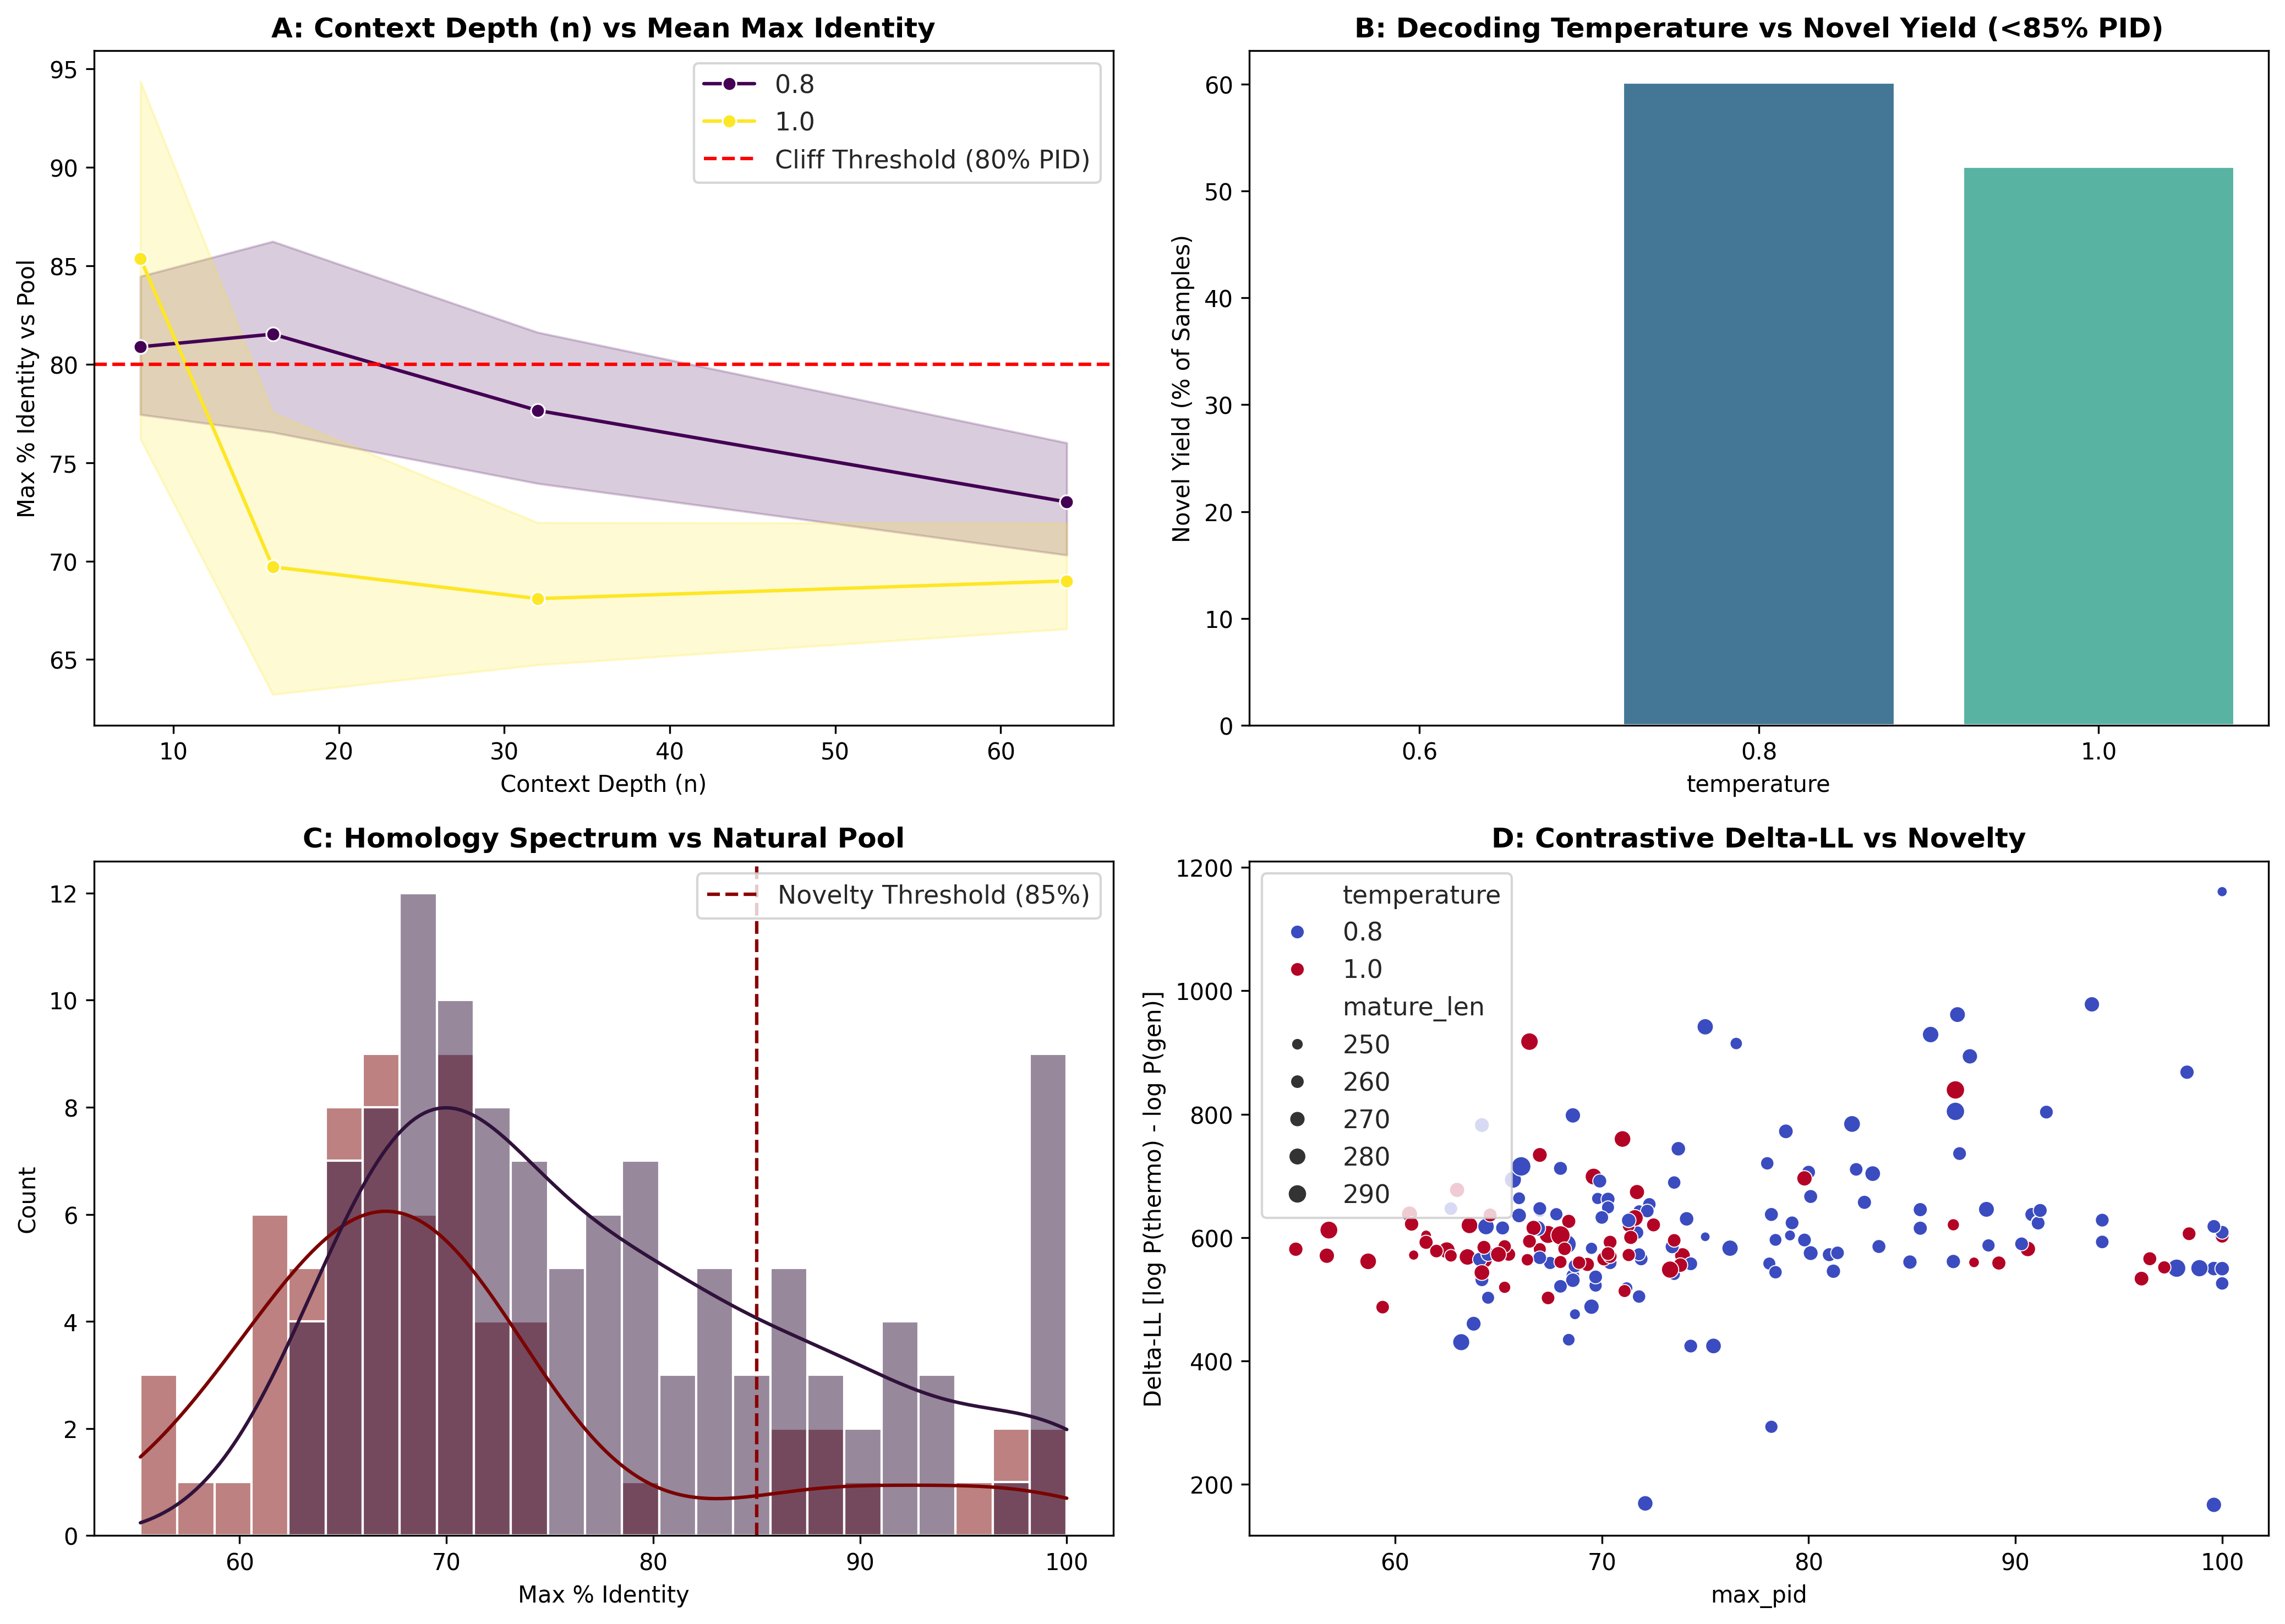

Saved figure to novelty_validity_pareto_sweeps.png


In [11]:
#@title Publication Multi-Panel Visualization
import matplotlib.pyplot as plt
import seaborn as sns

df_all = pd.DataFrame(all_candidates_flat)
df_coh = df_all[df_all["is_coherent"]].copy()

# 1. Memorization Cliff Audit
cliff_summary = []
for n, group in df_coh.groupby("n_examples"):
    mean_pid = group["max_pid"].mean()
    novel_pct = (group["max_pid"] < MAX_ID).mean() * 100.0
    cliff_summary.append({
        "n_examples": n,
        "mean_max_pid": round(mean_pid, 2),
        "novel_yield_pct": round(novel_pct, 2),
        "count": len(group),
    })
cliff_df = pd.DataFrame(cliff_summary).sort_values("n_examples")
print("Memorization Cliff Audit across Context Depths (n):")
display(cliff_df)

# 2. Figure
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=300)
sns.set_theme(style="whitegrid")

# Panel A: Context Depth vs Max Identity
ax1 = axes[0, 0]
sns.lineplot(data=df_coh, x="n_examples", y="max_pid", hue="temperature", marker="o", palette="viridis", ax=ax1)
ax1.axhline(80.0, color="red", linestyle="--", label="Cliff Threshold (80% PID)")
ax1.set_title("A: Context Depth (n) vs Mean Max Identity", fontsize=12, fontweight="bold")
ax1.set_xlabel("Context Depth (n)")
ax1.set_ylabel("Max % Identity vs Pool")
ax1.legend()

# Panel B: Temperature vs Novel Yield
ax2 = axes[0, 1]
t_summary = df_all.groupby("temperature").agg(
    coherent_pct=("is_coherent", lambda x: x.mean() * 100),
    novel_pct=("is_novel", lambda x: x.mean() * 100),
).reset_index()
sns.barplot(data=t_summary, x="temperature", y="novel_pct", palette="mako", ax=ax2)
ax2.set_title("B: Decoding Temperature vs Novel Yield (<85% PID)", fontsize=12, fontweight="bold")
ax2.set_ylabel("Novel Yield (% of Samples)")

# Panel C: Homology Spectrum
ax3 = axes[1, 0]
sns.histplot(data=df_coh, x="max_pid", hue="temperature", bins=25, kde=True, palette="turbo", ax=ax3)
ax3.axvline(85.0, color="darkred", linestyle="--", label="Novelty Threshold (85%)")
ax3.set_title("C: Homology Spectrum vs Natural Pool", fontsize=12, fontweight="bold")
ax3.set_xlabel("Max % Identity")
ax3.legend()

# Panel D: Validity vs Temperature / Delta-LL
ax4 = axes[1, 1]
if "delta_ll" in df_coh.columns and df_coh["delta_ll"].nunique() > 1:
    sns.scatterplot(data=df_coh, x="max_pid", y="delta_ll", hue="temperature", size="mature_len", palette="coolwarm", ax=ax4)
    ax4.set_title("D: Contrastive Delta-LL vs Novelty", fontsize=12, fontweight="bold")
    ax4.set_ylabel("Delta-LL [log P(thermo) - log P(gen)]")
else:
    sns.lineplot(data=t_summary, x="temperature", y="coherent_pct", marker="s", color="green", ax=ax4)
    ax4.set_title("D: Coherent Yield vs Temperature", fontsize=12, fontweight="bold")
    ax4.set_ylabel("Coherent Folds (%)")

plt.tight_layout()
plt.savefig("novelty_validity_pareto_sweeps.png")
plt.show()
print("Saved figure to novelty_validity_pareto_sweeps.png")


## 10 · Export Deliverables

Exports:
1. `generated_continuations_grid.tsv` — Complete ledger of all generated sequences and biophysical attributes.
2. `designs_exp3_screened_novel.faa` — Screened mature amino acid FASTA of all novel, coherent leads clearing $\max \text{PID} < 85.0\%$.


In [12]:
#@title Export TSV and Screened Candidate FASTA
import pandas as pd, pathlib

OUTPUTS = pathlib.Path("outputs")
OUTPUTS.mkdir(exist_ok=True)

grid_tsv = OUTPUTS / "generated_continuations_grid.tsv"
df_all = pd.DataFrame(all_candidates_flat)
df_all.to_csv(grid_tsv, sep="\t", index=False)
print(f"Saved {len(df_all)} candidate records to {grid_tsv}")

novel_df = df_all[df_all["is_novel"]].copy()
if "delta_ll" in novel_df.columns:
    novel_df = novel_df.sort_values("delta_ll", ascending=False)

out_faa = OUTPUTS / "designs_exp3_screened_novel.faa"
with open(out_faa, "w") as f:
    for _, r in novel_df.iterrows():
        header = f"{r['design_id']} n={r['n_examples']} T={r['temperature']} max_pid={r['max_pid']}%"
        if "delta_ll" in r:
            header += f" delta_ll={r['delta_ll']}"
        f.write(f">{header}\n")
        seq = r["sequence_aa"]
        f.write("\n".join(seq[j:j+60] for j in range(0, len(seq), 60)) + "\n")

print(f"Saved {len(novel_df)} coherent, novel leads to {out_faa}")
print("Experiment 3 — Module 2 execution complete!")


Saved 395 candidate records to outputs/generated_continuations_grid.tsv
Saved 140 coherent, novel leads to outputs/designs_exp3_screened_novel.faa
Experiment 3 — Module 2 execution complete!


In [13]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [14]:
!mkdir /content/drive/MyDrive/Evo2_exp3

In [15]:
cp -r work/* /content/drive/MyDrive/Evo2_exp3

In [18]:
cp -r outputs/ /content/drive/MyDrive/Evo2_exp3

In [19]:
cp novelty_validity_pareto_sweeps.png /content/drive/MyDrive/Evo2_exp3